In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import LogisticRegression

# Classification models
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Datasets
from sklearn.datasets import load_diabetes
from sklearn.datasets import load_iris
from sklearn.datasets import load_breast_cancer

# Split dataset
from sklearn.model_selection import train_test_split

# Evaluation metrics
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Display graphs inside notebook
%matplotlib inline

In [2]:
# Load Diabetes dataset

diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create Linear Regression model

linear_model = LinearRegression()

# Train the model

linear_model.fit(X_train, y_train)

# Predict values

y_pred = linear_model.predict(X_test)

# Calculate errors

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Results")
print("-------------------------")
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
-------------------------
MSE : 2900.193628493482
RMSE: 53.85344583676593
R2 Score: 0.4526027629719195


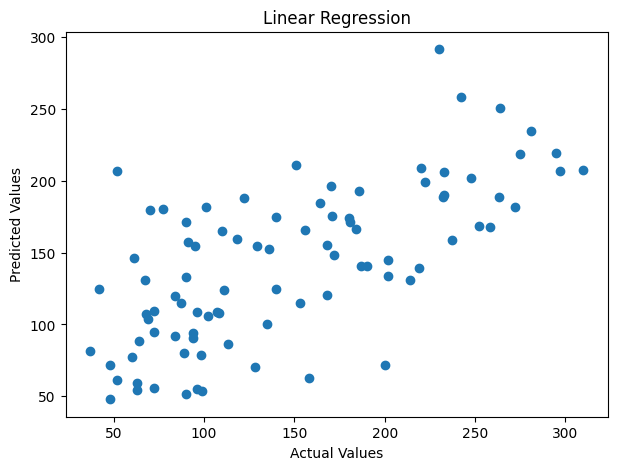

In [3]:
# Compare actual and predicted values

plt.figure(figsize=(7,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression")

plt.show()

In [4]:
# Create Ridge Regression model

ridge_model = Ridge(alpha=1.0)

# Train the model

ridge_model.fit(X_train, y_train)

# Predict values

ridge_pred = ridge_model.predict(X_test)

# Calculate performance

mse = mean_squared_error(y_test, ridge_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression Results")
print("------------------------")
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Ridge Regression Results
------------------------
MSE : 3077.41593882723
RMSE: 55.47446204180109
R2 Score: 0.41915292635986545


In [5]:
# Create Lasso Regression model

lasso_model = Lasso(alpha=0.1)

# Train the model

lasso_model.fit(X_train, y_train)

# Predict values

lasso_pred = lasso_model.predict(X_test)

# Calculate performance

mse = mean_squared_error(y_test, lasso_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, lasso_pred)

print("Lasso Regression Results")
print("------------------------")
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Lasso Regression Results
------------------------
MSE : 2798.193485169719
RMSE: 52.897953506442185
R2 Score: 0.4718547867276227


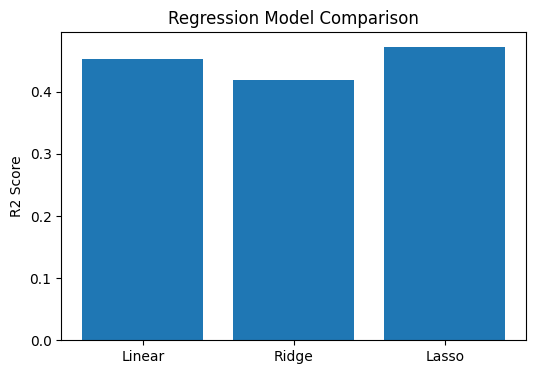

In [6]:
# Compare all regression models

models = ["Linear", "Ridge", "Lasso"]

r2_scores = [
    r2_score(y_test, y_pred),
    r2_score(y_test, ridge_pred),
    r2_score(y_test, lasso_pred)
]

plt.figure(figsize=(6,4))

plt.bar(models, r2_scores)

plt.ylabel("R2 Score")
plt.title("Regression Model Comparison")

plt.show()

In [7]:
#################################### QUESTION 1B #############

# Load the iris dataset

iris = load_iris()

X = iris.data
y = iris.target

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [8]:
# Create Decision Tree using Gini Index

gini_tree = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

# Train the model

gini_tree.fit(X_train, y_train)

# Predict

gini_pred = gini_tree.predict(X_test)

# Accuracy

accuracy = accuracy_score(y_test, gini_pred)

print("Decision Tree (Gini)")
print("--------------------")
print("Accuracy :", accuracy)

Decision Tree (Gini)
--------------------
Accuracy : 1.0


In [9]:
# Create Decision Tree using Entropy

entropy_tree = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

# Train

entropy_tree.fit(X_train, y_train)

# Predict

entropy_pred = entropy_tree.predict(X_test)

# Accuracy

accuracy = accuracy_score(y_test, entropy_pred)

print("Decision Tree (Entropy)")
print("-----------------------")
print("Accuracy :", accuracy)

Decision Tree (Entropy)
-----------------------
Accuracy : 1.0


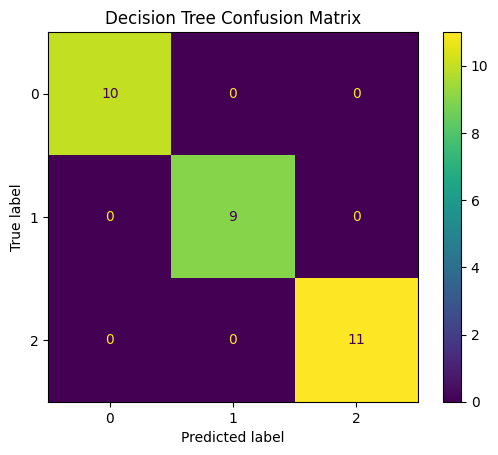

In [10]:
# Display confusion matrix

cm = confusion_matrix(y_test, entropy_pred)

ConfusionMatrixDisplay(cm).plot()

plt.title("Decision Tree Confusion Matrix")

plt.show()

In [11]:
# Print classification report

print(classification_report(y_test, entropy_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [12]:
print("Decision Tree Splitting Criteria")
print("--------------------------------")
print("Gini Impurity : Measures impurity in a node.")
print("Entropy : Measures randomness in the data.")
print("Information Gain : Reduction in entropy after splitting.")

Decision Tree Splitting Criteria
--------------------------------
Gini Impurity : Measures impurity in a node.
Entropy : Measures randomness in the data.
Information Gain : Reduction in entropy after splitting.


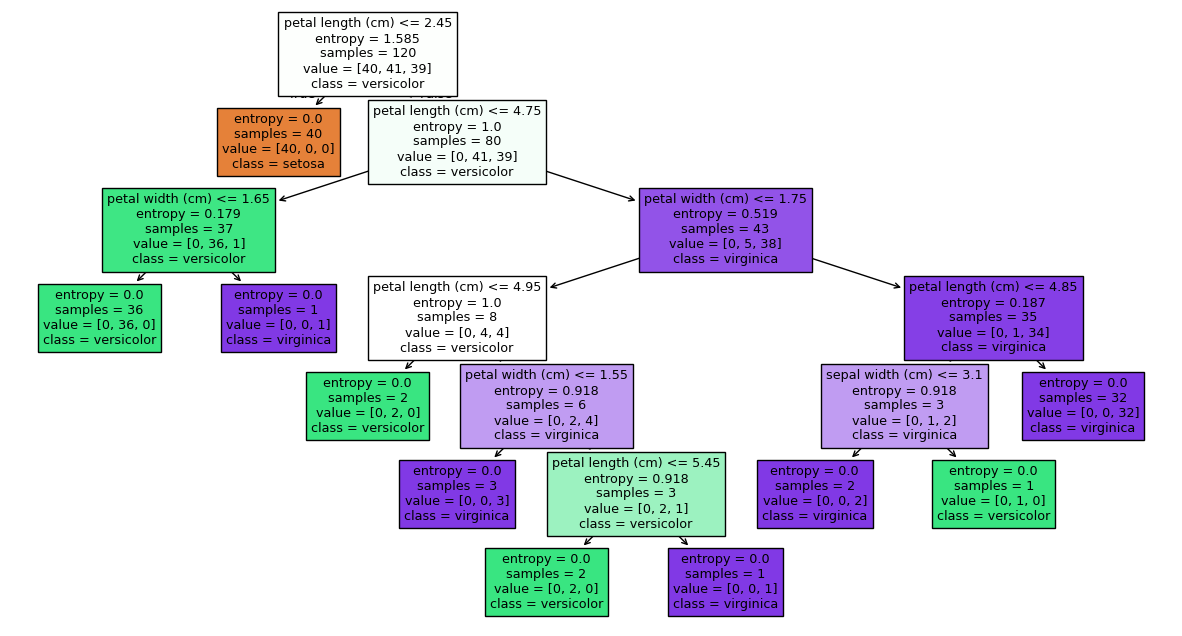

In [13]:
from sklearn.tree import plot_tree

plt.figure(figsize=(15,8))

plot_tree(
    entropy_tree,
    filled=True,
    feature_names=iris.feature_names,
    class_names=iris.target_names
)

plt.show()

In [14]:
####################### 1C ##########################

# Load Breast Cancer dataset

cancer = load_breast_cancer()

X = cancer.data
y = cancer.target

# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [15]:
# Create Logistic Regression model

log_model = LogisticRegression(
    max_iter=5000
)

# Train model

log_model.fit(X_train, y_train)

# Predict

log_pred = log_model.predict(X_test)

# Accuracy

accuracy = accuracy_score(y_test, log_pred)

print("Logistic Regression")
print("-------------------")
print("Accuracy :", accuracy)

Logistic Regression
-------------------
Accuracy : 0.956140350877193


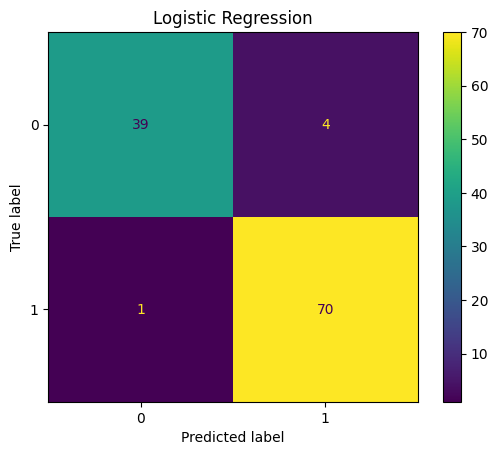

In [16]:
cm = confusion_matrix(y_test, log_pred)

ConfusionMatrixDisplay(cm).plot()

plt.title("Logistic Regression")

plt.show()

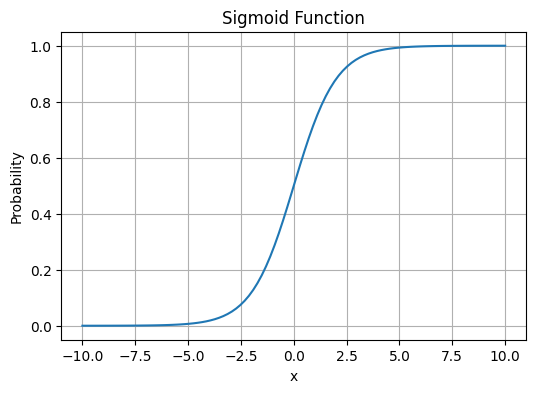

In [17]:
# Plot Sigmoid Function

x = np.linspace(-10,10,100)

y = 1/(1+np.exp(-x))

plt.figure(figsize=(6,4))

plt.plot(x,y)

plt.title("Sigmoid Function")

plt.xlabel("x")

plt.ylabel("Probability")

plt.grid()

plt.show()

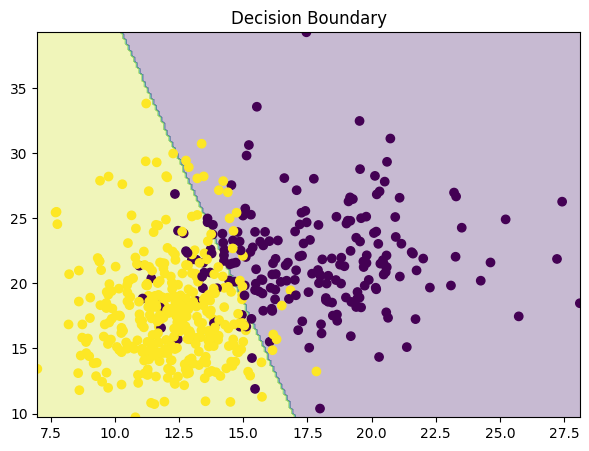

In [18]:
# Use only first two features for visualization

X = cancer.data[:, :2]
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LogisticRegression(max_iter=5000)

model.fit(X_train, y_train)

xx, yy = np.meshgrid(
    np.linspace(X[:,0].min(), X[:,0].max(),200),
    np.linspace(X[:,1].min(), X[:,1].max(),200)
)

Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(7,5))

plt.contourf(xx,yy,Z,alpha=0.3)

plt.scatter(
    X[:,0],
    X[:,1],
    c=y
)

plt.title("Decision Boundary")

plt.show()

In [19]:
# Logistic Regression using L2 Regularization

ridge_log = LogisticRegression(
    penalty="l2",
    solver="liblinear",
    max_iter=5000
)

ridge_log.fit(X_train,y_train)

pred = ridge_log.predict(X_test)

print("Accuracy :", accuracy_score(y_test,pred))

Accuracy : 0.9210526315789473


In [20]:
# Logistic Regression using L1 Regularization

lasso_log = LogisticRegression(
    penalty="l1",
    solver="liblinear",
    max_iter=5000
)

lasso_log.fit(X_train,y_train)

pred = lasso_log.predict(X_test)

print("Accuracy :", accuracy_score(y_test,pred))

Accuracy : 0.9035087719298246


In [21]:
############################################# 1D ###########################################

# Load iris dataset

iris = load_iris()

X = iris.data
y = iris.target

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create KNN model

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train,y_train)

pred = knn.predict(X_test)

print("KNN Accuracy :",accuracy_score(y_test,pred))

KNN Accuracy : 1.0


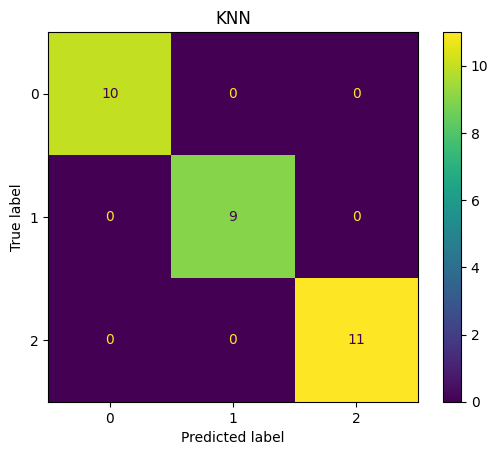

In [22]:
cm = confusion_matrix(y_test,pred)

ConfusionMatrixDisplay(cm).plot()

plt.title("KNN")

plt.show()

In [23]:
################################# 1E ###################################

# Create Gaussian Naive Bayes model

nb = GaussianNB()

nb.fit(X_train,y_train)

pred = nb.predict(X_test)

print("Naive Bayes Accuracy :",accuracy_score(y_test,pred))

Naive Bayes Accuracy : 1.0


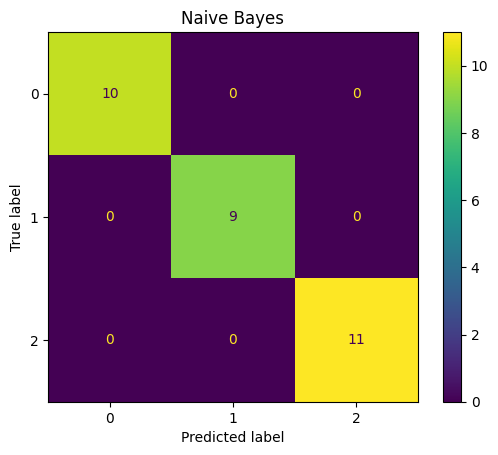

In [24]:
cm = confusion_matrix(y_test,pred)

ConfusionMatrixDisplay(cm).plot()

plt.title("Naive Bayes")

plt.show()

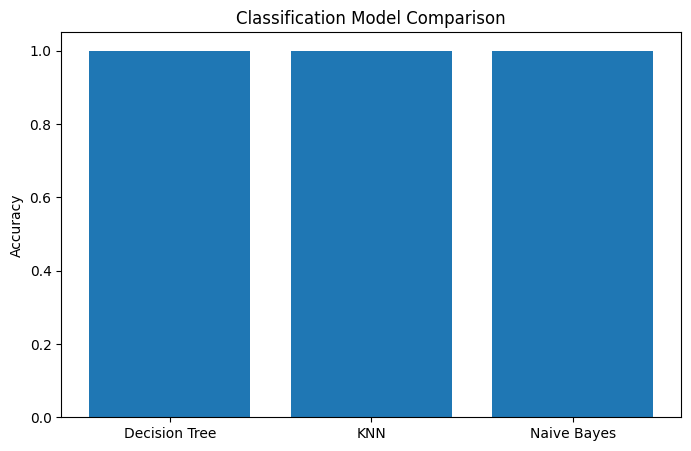

In [27]:
# Compare models trained on the Iris dataset

models = [
    "Decision Tree",
    "KNN",
    "Naive Bayes"
]

scores = [
    accuracy_score(y_test, entropy_pred),
    accuracy_score(y_test, knn.predict(X_test)),
    accuracy_score(y_test, nb.predict(X_test))
]

plt.figure(figsize=(8,5))

plt.bar(models, scores)

plt.ylabel("Accuracy")

plt.title("Classification Model Comparison")

plt.show()